# ERCOT - Outage DATA

Cleaning spec: 

- Category: keep only Total Resource. Drop IRR (wind/solar) and New Equipment.
- Geography: sum the zones to a system-wide outage_MW. Early 2021 already has a system total.
- Which posting to use: The archive parquet, the 1-hour-ahead forecast for every (Date, HourEnding), used the same way across all years. 
- Timestamps: hour-ending, the project standard, plus the usual DST checks.
- Where it's used: the denominator of spare_capacity_v2 = (load − renewable_gen) / (thermal_capacity − outage_MW) in 03_v2_data_prep.

NOTE: 
1. 2021-01 to 2021-05 have only the system total, not seperated by zones; we will use the system total column for all years
2. 2024-07-23 HE 17 have no data, ERCOT site problem

## 1. Imports & paths

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

PROJECT_ROOT = Path('../..').resolve()
ARCHIVE_PATHS = [
    PROJECT_ROOT / '01_data' / '1.2_raw_api' / 'outage' / 'outage_cap_archive_20210101_20260924.parquet',
    PROJECT_ROOT / '01_data' / '1.2_raw_api' / 'outage' / 'outage_cap_archive_20260901_20261028.parquet',
]

OUT_DIR      = PROJECT_ROOT / '01_data' / '2_cleaned' / 'outage'
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load & inspect

In [2]:
# the two pulls overlap on 2026-09-01 → 09-24; identical postings are dropped
df_archive = pd.concat([pd.read_parquet(p) for p in ARCHIVE_PATHS], ignore_index=True)
n_raw = len(df_archive)
df_archive = df_archive.drop_duplicates(['postedDatetime', 'operatingDate', 'hourEnding'])
print(f'{n_raw} rows -> {len(df_archive)} after dropping overlapping postings')

9806112 rows -> 9698208 after dropping overlapping postings


In [3]:
df_filtered = df_archive.filter(['postedDatetime', 'operatingDate', 'hourEnding', 'totalResourceMW', 'totalResourceMWZoneSouth', 'totalResourceMWZoneNorth', 'totalResourceMWZoneWest', 'totalResourceMWZoneHouston'])
df_filtered.head()

,postedDatetime,operatingDate,hourEnding,totalResourceMW,totalResourceMWZoneSouth,totalResourceMWZoneNorth,totalResourceMWZoneWest,totalResourceMWZoneHouston
0,2021-01-01T00:01:25.646,2021-01-01,1,7754.0,NaN,NaN,NaN,NaN
1,2021-01-01T00:01:25.646,2021-01-01,2,7754.0,NaN,NaN,NaN,NaN
2,2021-01-01T00:01:25.646,2021-01-01,3,7754.0,NaN,NaN,NaN,NaN
3,2021-01-01T00:01:25.646,2021-01-01,4,7754.0,NaN,NaN,NaN,NaN
4,2021-01-01T00:01:25.646,2021-01-01,5,7754.0,NaN,NaN,NaN,NaN


In [4]:
df_filtered['postedDatetime']

0          2021-01-01T00:01:25.646
1          2021-01-01T00:01:25.646
2          2021-01-01T00:01:25.646
3          2021-01-01T00:01:25.646
4          2021-01-01T00:01:25.646
                    ...           
9806107    2026-10-28T11:00:46.000
9806108    2026-10-28T11:00:46.000
9806109    2026-10-28T11:00:46.000
9806110    2026-10-28T11:00:46.000
9806111    2026-10-28T11:00:46.000
Name: postedDatetime, Length: 9698208, dtype: str

In [5]:
# profiling table
summary = pd.DataFrame({
    'data_types': df_filtered.dtypes,
    'n_missing': [df_filtered[col].isna().sum() for col in df_filtered.columns],
    'missing_rate_%': [round(df_filtered[col].isna().mean()*100, 2) for col in df_filtered.columns],
    'n_unique': [df_filtered[col].nunique() for col in df_filtered.columns],
    'sample_entries': [list(df_filtered[col].unique()[:3]) for col in df_filtered.columns]
})
summary

,data_types,n_missing,missing_rate_%,n_unique,sample_entries
postedDatetime,str,0,0.0,51017,"[2021-01-01T00:01:25.646, 2021-01-01T01:01:23...."
operatingDate,str,0,0.0,2134,"[2021-01-01, 2021-01-02, 2021-01-03]"
hourEnding,int64,0,0.0,24,"[1, 2, 3]"
totalResourceMW,float64,0,0.0,31308,"[7754.0, 7454.0, 7332.0]"
totalResourceMWZoneSouth,float64,591360,6.1,12777,"[nan, 2530.0, 3100.0]"
totalResourceMWZoneNorth,float64,591360,6.1,13222,"[nan, 5604.0, 6409.0]"
totalResourceMWZoneWest,float64,591360,6.1,2355,"[nan, 817.0, 777.0]"
totalResourceMWZoneHouston,float64,591360,6.1,7632,"[nan, 1489.0, 1389.0]"


In [6]:
# use totalResourceMW directly
df_filtered = df_filtered.filter(['postedDatetime', 'operatingDate', 'hourEnding', 'totalResourceMW'])

## 2.5 Cleaning (Datetime column and total outage)

In [7]:
df = df_filtered.copy()

df['datetime'] = pd.to_datetime(df['operatingDate']) + pd.to_timedelta(df['hourEnding'], unit='h')
df['pdt'] = pd.to_datetime(df['postedDatetime'], format='ISO8601')

last_hour = df['pdt'].max().ceil('h')

h1 = (df[(df['pdt'] < df['datetime']) & (df['datetime'] <= last_hour)]
        .sort_values('pdt')
        .drop_duplicates('datetime', keep='last')
        .sort_values('datetime')
        .reset_index(drop=True))

h1['lead_min'] = (h1['datetime'] - h1['pdt']).dt.total_seconds() / 60
h1['stale'] = h1['lead_min'] > 61

print(len(h1), h1['datetime'].is_unique)
print(h1['lead_min'].describe())

51036 True
count    51036.000000
mean        58.204249
std          1.860542
min          6.984500
25%         57.583825
50%         58.229917
75%         58.966667
max        178.197550
Name: lead_min, dtype: float64


In [8]:
df = h1.filter(['datetime', 'totalResourceMW'])

## 3. Summary statistics

In [9]:
print('=== ERCOT — Hourly Outage Statistics ===')
df.describe()

=== ERCOT — Hourly Outage Statistics ===


,datetime,totalResourceMW
count,51036,51036.000000
mean,2023-11-30 06:30:00,14804.255016
min,2021-01-01 01:00:00,0.000000
25%,2022-06-16 15:45:00,8300.000000
50%,2023-11-30 06:30:00,12317.000000
75%,2025-05-14 21:15:00,21382.250000
max,2026-10-28 12:00:00,34750.000000
std,NaN,7635.690668


## 4. Time Series Line Chart

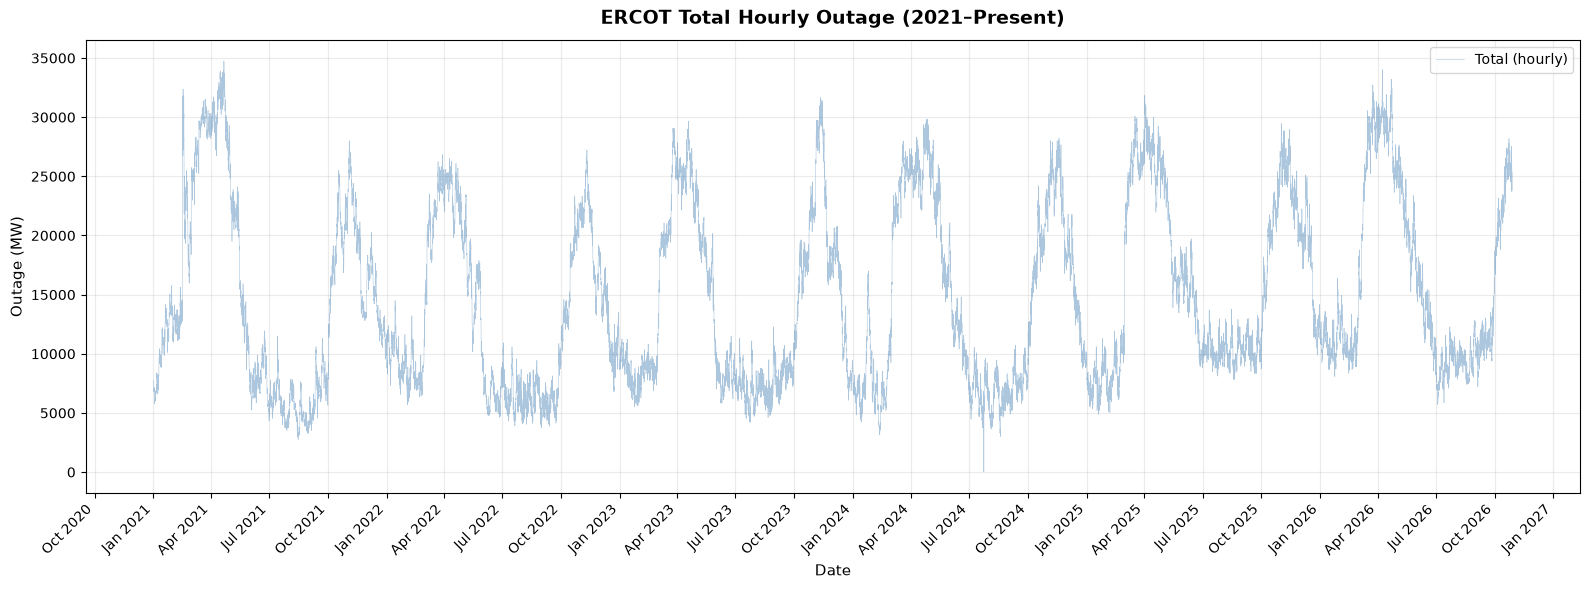

In [ ]:
# 7-day rolling average for trend overlay
df = df.copy()

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(df['datetime'], df['totalResourceMW'],
        color='steelblue', linewidth=0.4, alpha=0.45, label='Total (hourly)')

ax.set_title('ERCOT Total Hourly Outage (2021–Present)',
             fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel('Outage (MW)', fontsize=11)
ax.set_xlabel('Date', fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.25)

ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45, ha='right')

fig.tight_layout()
plt.show()

## 5. Save File

In [11]:
out_path = OUT_DIR / f"archive_1h_ahead_outage_20210101_{df['datetime'].max():%Y_%m%d}.parquet"
df.to_parquet(out_path)

In [12]:
print(out_path)

/Users/zyliazhang/Git/ERCOT-Research/01_data/2_cleaned/outage/archive_1h_ahead_outage_20210101_2026_1028.parquet
